In [35]:
import numpy as np
from experiments_utils import ICS26_DIR
from src.surrogate import HATANNSurrogate
from src.problems.lorenz96_flowmap import lorenz96_flowmap, lorenz96_flowmap_grad
from pathlib import Path
from ics26_experiments import (
    get_N_TRAIN,
    get_N_INIT_CLUSTERS,
    get_N_MIN_PER_CLUSTER
)

# Parameters for surrogate training (from train)
DIM = 5
TOL = 0.02
ERROR_METRIC = 'Linf-global'
DOMAIN = [-5.0, 5.0]
SEED = 0
FORCING = 1
DT = 0.1
N_TRAIN = get_N_TRAIN(DIM)
N_TIMESTEPS = 20
N_INIT_CLUSTERS = get_N_INIT_CLUSTERS(DIM)
N_MIN_PER_CLUSTER = get_N_MIN_PER_CLUSTER(DIM)


def f(x, output_var: int):
    f = lorenz96_flowmap(x, FORCING, DT)  # (N, d) vector
    N, d = f.shape
    return f[:, output_var].reshape((N, 1))

def f_full(x):
    return lorenz96_flowmap(x, FORCING, DT)  # (N, d) vector

def grad_f(x, output_var: int):
    g = lorenz96_flowmap_grad(x, FORCING, DT)
    N, d, _ = g.shape
    return g[:, output_var, :].reshape((N, 1, d))

def grad_f_full(x):
    return lorenz96_flowmap_grad(x, FORCING, DT)


In [36]:
# Load data
surrogates = [HATANNSurrogate(version='v2') for _ in range(DIM)]
for i in range(DIM):
    lorenz_path = Path.cwd() / 'lorenz_surrogates'
    model_path = lorenz_path / f"lorenz96_dim{DIM}_F{FORCING}_tol{TOL}_tf{DT}_outputvar_{i}.npz"
    surrogates[i].train(
        X_train=None,
        f_fn=lambda x: f(x, i),
        g_fn=lambda x: grad_f(x, i),
        TOL=TOL,
        ERROR_METRIC=ERROR_METRIC,
        NUM_INITIAL_CLUSTERS=N_INIT_CLUSTERS,
        MIN_PTS_PER_CLUSTER=N_MIN_PER_CLUSTER,
        MAX_CLUSTERS_EST=20_000,
        SEED=SEED,
        USE_HESSIAN_INFORMED_SPLIT=True,
        IGNORE_GRADIENT=False,
        save_model=model_path,
        load_if_exists=True
    )
    print(f'Num Clusters for Surrogate {i}: {surrogates[i].get_number_of_sources()}')


Num Clusters for Surrogate 0: 1278
Num Clusters for Surrogate 1: 1512
Num Clusters for Surrogate 2: 1296
Num Clusters for Surrogate 3: 1329
Num Clusters for Surrogate 4: 1435


In [37]:
# Parameters for ode solves
TF = 10.0
tvec = np.arange(0, TF+DT, DT)
NSTEPS = int(TF / DT)
N_trajectories = 500

# Pick initial points used for measuring mean and std errors (bottom right plot)
np.random.seed(108)
x0_scattered_trajectories = np.random.uniform(-3, 3, (N_trajectories, DIM)) + FORCING

# True solution
from src.problems.lorenz96 import lorenz96
from scipy.integrate import solve_ivp
def lorenz_rhs(t, x:np.ndarray):
    return lorenz96(x.reshape(1,DIM), forcing=FORCING).flatten()

scattered_trajectories_exact = np.zeros(shape=(N_trajectories, DIM, NSTEPS+1))
for j, x0 in enumerate(x0_scattered_trajectories):
    struct = solve_ivp(lorenz_rhs, [0, TF], x0.flatten(), 'RK45', rtol=1e-6, t_eval=tvec)
    scattered_trajectories_exact[j] = struct.y

# Surrogate solution (many of them)
scattered_trajectories_surr = np.zeros(shape=(N_trajectories, DIM, NSTEPS+1))
scattered_trajectories_surr[:,:,0] = x0_scattered_trajectories
for j in range(NSTEPS):
    for k, surrogate in enumerate(surrogates):
        pred, _ = surrogate.predict(scattered_trajectories_surr[:,:,j], k_nn=1)
        scattered_trajectories_surr[:,k,j+1] = pred.flatten()

# Compute errors
fmax = np.max(np.abs(scattered_trajectories_exact))
error = scattered_trajectories_surr - scattered_trajectories_exact
# Compute distances (collapse DIM), keep timesteps and trajectories constant
abs_error = np.linalg.norm(error, axis=1)
rel_error = abs_error / fmax
# Then compute mean and std, for each timestep (collapse N_trajectories)
mean = np.mean(rel_error, axis=0) # (NSTEPS)
std = np.std(rel_error, axis=0)


In [38]:
# Pick initial points used for trajectory cloud
eps = 0.05
N_trajectories_in_cloud = 30
x0 = np.random.uniform(-3, 3, (1,DIM)) + FORCING
# x0 = np.array([[2.0, 2.0, -2.0, 2.0, 2.5]])
x0_trajectory_cloud = np.tile(x0, (N_trajectories_in_cloud, 1))
x0_trajectory_cloud += eps * np.random.randn(N_trajectories_in_cloud, DIM)

struct = solve_ivp(lorenz_rhs, [0, TF], x0.flatten(), 'RK45', rtol=1e-6, t_eval=tvec)
trajectory_cloud_exact_center = struct.y
trajectory_cloud_surr_center = np.zeros_like(trajectory_cloud_exact_center)
trajectory_cloud_surr_center[:,0] = x0

# Surrogate solution (many of them)
trajectory_cloud_surr = np.zeros(shape=(N_trajectories_in_cloud, DIM, NSTEPS+1))
trajectory_cloud_surr[:,:,0] = x0_trajectory_cloud
for j in range(NSTEPS):
    for k, surrogate in enumerate(surrogates):
        pred, _ = surrogate.predict(trajectory_cloud_surr[:,:,j], k_nn=1)
        trajectory_cloud_surr[:,k,j+1] = pred.flatten()
        pred, _ = surrogate.predict(trajectory_cloud_surr_center[:,j].reshape(1,DIM), k_nn=1)
        trajectory_cloud_surr_center[k,j+1] = pred.flatten()


/var/folders/pc/_rlr7wmn33s7hb9l9kpgsj3w0000gn/T/ipykernel_18311/1025539817.py:22: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  trajectory_cloud_surr_center[k,j+1] = pred.flatten()


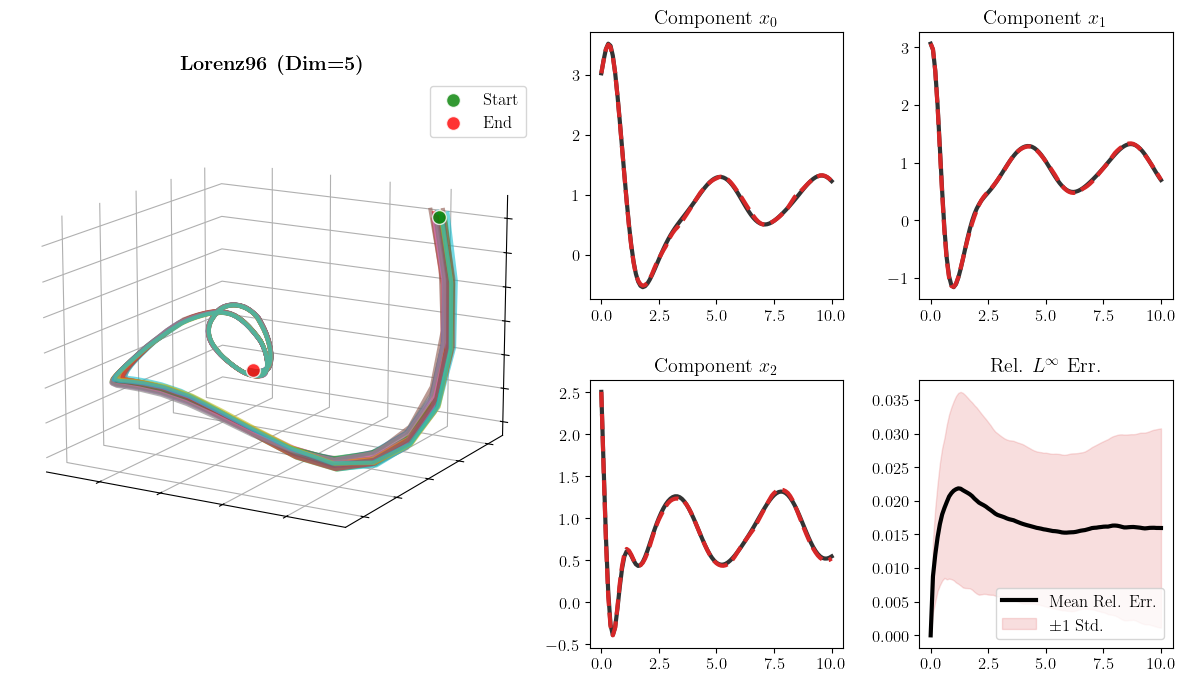

In [47]:
# Prajwal's plot code
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt

# Plotting
plt.rcParams.update(
    {"text.usetex": True, "font.family": "serif", "figure.figsize": (15, 8),
     "font.size": 12}
)
fig = plt.figure()
gs = GridSpec(1, 2, width_ratios=[0.9, 1], wspace=0.1)

# 3D Phase Space (First 3 components)
ax3d = fig.add_subplot(gs[0], projection="3d")

n_points = trajectory_cloud_exact_center.shape[1]
for i in range(trajectory_cloud_surr.shape[0]):
    # plot_data[i, 0, :] is x-coords for trajectory i
    # plot_data[i, 1, :] is y-coords for trajectory i
    # plot_data[i, 2, :] is z-coords for trajectory i
    ax3d.plot(trajectory_cloud_surr[i, 0, :],
              trajectory_cloud_surr[i, 1, :],
              trajectory_cloud_surr[i, 2, :],
              alpha=0.6, linewidth=3.0)
    
# Start circle
ax3d.scatter(trajectory_cloud_exact_center[0, 0],
             trajectory_cloud_exact_center[1, 0],
             trajectory_cloud_exact_center[2, 0],
             c='green', s=100, edgecolors='white', alpha=0.8,
             label='Start')

# End circle
ax3d.scatter(trajectory_cloud_exact_center[0, -1],
             trajectory_cloud_exact_center[1, -1],
             trajectory_cloud_exact_center[2, -1],
             c='red', s=100, edgecolors='white', alpha=0.8,
             label='End')

# ax3d.scatter(true[0, 0], true[1, 0], true[2, 0], color="green", s=50, label="Start")
# ax3d.scatter(true[0, -1], true[1, -1], true[2, -1], color="red", s=50, label="End")
ax3d.view_init(elev=15, azim=-60)
ax3d.set_title(rf"\textbf{{Lorenz96 (Dim={DIM})}}")
ax3d.legend()

# Components and Error
gs_sub = gs[1].subgridspec(2, 2, hspace=0.3, wspace=0.3)
labels = ["x_0", "x_1", "x_2"]

# For one trajectory: plot only first 3 components
for i in range(3):
    ax = fig.add_subplot(gs_sub[i // 2, i % 2])
    ax.plot(tvec, trajectory_cloud_exact_center[i, :], color="#333333", lw=3)
    ax.plot(tvec, trajectory_cloud_surr_center[i, :], color="#d62728", ls="--", lw=3)
    ax.set_title(f"Component ${labels[i]}$")

# Error Plot
ax_err = fig.add_subplot(gs_sub[1, 1])
ax_err.plot(tvec, mean, color="#000000", lw=3, label='Mean Rel. Err.')
ax_err.fill_between(tvec, mean+std, mean-std, color="#d62728", alpha=0.15,
                    label='$\\pm 1$ Std.')
ax_err.set_title(f"Rel. $L^\\infty$ Err.")
ax_err.legend(loc='lower right')

# # Error plot #2
# ax_err = fig.add_subplot(gs_sub[1, 1])
# ax_err.hist2d(tvec, rel_error, bins=[NSTEPS+1, 50], cmap='Blues', cmin=1)

# Clean it up
ax3d.set_xticklabels([])
ax3d.set_yticklabels([])
ax3d.set_zticklabels([])

ax3d.xaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
ax3d.yaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
ax3d.zaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))

# Optional: If you want to remove the tick marks (the little lines) as well

plt.show()
